In [2]:
import os
import re
import time
import warnings
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from skimage.feature import hog
from skimage.measure import regionprops

from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.svm import SVC
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

warnings.filterwarnings('ignore')

# --- TỰ ĐỘNG TÌM ĐƯỜNG DẪN DATASET ---
print("Dang quet tim thu muc dataset...")
base_input_dir = Path("/kaggle/input")
dataset_dir_found = None

for root, dirs, files in os.walk(base_input_dir):
    if "CktComDb-v1.o" in dirs and "CktComDb-v1.a" in dirs and "CktComDb-v1.oa" in dirs:
        dataset_dir_found = Path(root)
        break

assert dataset_dir_found is not None, "LỖI: Không tìm thấy thư mục CktComDb-v1.o, .a, .oa trong /kaggle/input!"

DATASET_DIR = dataset_dir_found
ORIGINAL_DIR = DATASET_DIR / "CktComDb-v1.o"
AUGMENTED_DIR = DATASET_DIR / "CktComDb-v1.a"
MIXED_DIR = DATASET_DIR / "CktComDb-v1.oa"

print(f"-> Da tim thay dataset tai: {DATASET_DIR}")

CLASS_NAMES = [
    "AC Source", "Ammeter", "AND Gate", "Capacitor",
    "DC Source", "Ground", "Inductor", "NAND Gate",
    "NOR Gate", "NOT Gate", "NPN Transistor", "OR Gate",
    "PN Junction Diode", "PNP Transistor", "Power Supply",
    "Resistor", "Switch", "Transformer", "Voltmeter", "Zener Diode"
]
CLASSES = [f"{i:02d}" for i in range(1, 21)]
LABEL_MAP = dict(zip(CLASSES, CLASS_NAMES))

print("Dataset Kaggle da san sang!")

Dang quet tim thu muc dataset...
-> Da tim thay dataset tai: /kaggle/input/datasets/ayush02102001/circuit-component-analysis
Dataset Kaggle da san sang!


In [3]:
def find_split_dir(base_dir, split_name):
    direct_path = base_dir / split_name
    if direct_path.is_dir(): return direct_path
    lower_path = base_dir / split_name.lower()
    if lower_path.is_dir(): return lower_path
    subdirs = [d for d in base_dir.iterdir() if d.is_dir()]
    if len(subdirs) == 1: return find_split_dir(subdirs[0], split_name)
    return None

def get_images(root, split):
    split_dir = find_split_dir(root, split)
    assert split_dir is not None, f"Không tìm thấy thư mục {split} trong {root}"
    
    paths = []
    for cls in CLASSES:
        folder = split_dir / cls
        assert folder.is_dir(), f"Missing class folder: {folder}"
        files = sorted([f for f in folder.iterdir() if f.suffix.lower() in ['.bmp', '.jpg', '.png']])
        paths.extend(files)
    return paths

print("Dang load danh sach file anh...")
originals = get_images(ORIGINAL_DIR, "Train")
augmentations = get_images(AUGMENTED_DIR, "Train")
all_test_paths = get_images(MIXED_DIR, "Test")

print(f"-> Load thanh cong: Originals: {len(originals)} | Augmented: {len(augmentations)} | Test: {len(all_test_paths)}")

Dang load danh sach file anh...
-> Load thanh cong: Originals: 1000 | Augmented: 9000 | Test: 20000


In [4]:
def original_key(path):
    match = re.fullmatch(r"original_(\d+)", path.stem, re.I)
    if match is None: raise ValueError(f"Invalid original file: {path.name}")
    return (path.parent.name, int(match.group(1)))

def augmented_key(path):
    match = re.fullmatch(r"augmented_(\d+)_(\d+)", path.stem, re.I)
    if match is None: raise ValueError(f"Invalid augmented file: {path.name}")
    return (path.parent.name, int(match.group(2)))

SEED = 42
train_orig, val_orig = train_test_split(
    originals, test_size=0.2, stratify=[p.parent.name for p in originals], random_state=SEED
)

train_ids = {original_key(p) for p in train_orig}
val_ids = {original_key(p) for p in val_orig}

train_aug = [p for p in augmentations if augmented_key(p) in train_ids]
val_aug = [p for p in augmentations if augmented_key(p) in val_ids]

train_paths = sorted(train_orig + train_aug)
val_paths = sorted(val_orig + val_aug)
test_paths = sorted(all_test_paths)

y_train = np.array([p.parent.name for p in train_paths])
y_val   = np.array([p.parent.name for p in val_paths])
y_test  = np.array([p.parent.name for p in test_paths])

print("===== KET QUA CHIA TAP =====")
print(f"Train: {len(train_paths)} | Validation: {len(val_paths)} | Test: {len(test_paths)}")

===== KET QUA CHIA TAP =====
Train: 8000 | Validation: 2000 | Test: 20000


In [5]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedShuffleSplit

# Danh sách các cấu hình SVM cần đối chiếu trên tập Validation
SVM_CONFIGS = [
    ("Linear (C=1.0)",  {"kernel": "linear", "C": 1.0}),
    ("Linear (C=10.0)", {"kernel": "linear", "C": 10.0}),
    ("RBF (C=1.0)",     {"kernel": "rbf",    "C": 1.0,  "gamma": "scale"}),
    ("RBF (C=10.0)",    {"kernel": "rbf",    "C": 10.0, "gamma": "scale"}),
]

def plot_misclassified(y_true, y_pred, paths, model_name, max_images=12):
    """Hiển thị lưới các ảnh dự đoán sai trên tập Test."""
    wrong_idx = np.where(y_true != y_pred)[0]
    print(f"\n[{model_name}] Tổng số ảnh dự đoán sai trên Test: {len(wrong_idx)} / {len(y_true)}")
    if len(wrong_idx) == 0:
        return

    rng = np.random.default_rng(SEED)
    sample_idx = rng.choice(wrong_idx, size=min(max_images, len(wrong_idx)), replace=False)

    cols = 4
    rows = int(np.ceil(len(sample_idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(13, 3.2 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, sample_idx):
        img = preprocess(paths[idx])
        true_lbl = LABEL_MAP[y_true[idx]]
        pred_lbl = LABEL_MAP[y_pred[idx]]
        ax.imshow(img, cmap="gray")
        ax.set_title(f"True: {true_lbl}\nPred: {pred_lbl}", color="crimson", fontsize=9.5, fontweight="bold")
        ax.axis("off")

    for ax in axes[len(sample_idx):]:
        ax.axis("off")

    plt.suptitle(f"Một số mẫu dự đoán sai (Test) — {model_name}", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


def select_and_evaluate(feat_name, X_tr, y_tr, X_v, y_v, X_te, y_te, te_paths):
    """Huấn luyện các cấu hình, chọn cấu hình tốt nhất theo Validation, đánh giá trên Test và hiệu chuẩn xác suất."""
    print(f"\n{'='*70}\nĐANG CHỌN CẤU HÌNH TRÊN VALIDATION CHO: {feat_name}\n{'='*70}")
    val_records = []
    best_val_acc = -1.0
    best_model = None
    best_cfg_name = None

    for cfg_name, params in SVM_CONFIGS:
        t0 = time.time()
        model = make_pipeline(
            StandardScaler(),
            SVC(cache_size=1000, random_state=SEED, **params)
        )
        model.fit(X_tr, y_tr)
        train_time = time.time() - t0

        y_val_pred = model.predict(X_v)
        val_acc = accuracy_score(y_v, y_val_pred)
        val_f1 = f1_score(y_v, y_val_pred, average="macro")

        val_records.append({
            "Đặc trưng": feat_name,
            "Cấu hình": cfg_name,
            "Val Acc (%)": round(val_acc * 100, 2),
            "Val Macro F1": round(val_f1, 4),
            "Train Time (s)": round(train_time, 2),
        })
        print(f"  - {cfg_name:<16} | Val Acc: {val_acc*100:.2f}% | Val F1: {val_f1:.4f} | Time: {train_time:.2f}s")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model = model
            best_cfg_name = cfg_name

    # Đánh giá chính thức mô hình tốt nhất trên tập Test
    full_name = f"{feat_name} + SVM {best_cfg_name}"
    print(f"\n>>> CHỌN CẤU HÌNH TỐT NHẤT TRÊN VAL: {best_cfg_name} (Val Acc: {best_val_acc*100:.2f}%)")
    print(f">>> ĐÁNH GIÁ CHÍNH THỨC TRÊN TEST: {full_name}")

    y_test_pred = best_model.predict(X_te)
    test_acc = accuracy_score(y_te, y_test_pred)
    test_f1 = f1_score(y_te, y_test_pred, average="macro")
    print(f"[TEST] Accuracy: {test_acc*100:.2f}% | Macro F1: {test_f1:.4f}\n")

    print("Báo cáo chi tiết (TEST):")
    print(classification_report([LABEL_MAP[l] for l in y_te],
                                [LABEL_MAP[l] for l in y_test_pred]))

    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay.from_predictions(
        y_te, y_test_pred, display_labels=CLASS_NAMES,
        xticks_rotation="vertical", cmap="Blues", ax=ax
    )
    plt.title(f"Confusion Matrix (Test) — {full_name}")
    plt.show()

    plot_misclassified(y_te, y_test_pred, te_paths, full_name, max_images=12)

    # --- HIỆU CHUẨN XÁC SUẤT TRÊN TẬP VALIDATION ĐỂ HIỂN THỊ CONFIDENCE ---
    try:
        from sklearn.frozen import FrozenEstimator
        calibrated_model = CalibratedClassifierCV(FrozenEstimator(best_model), method="sigmoid")
    except ImportError:
        calibrated_model = CalibratedClassifierCV(best_model, method="sigmoid", cv="prefit")

    calibrated_model.fit(X_v, y_v)
    sample_probs = calibrated_model.predict_proba(X_v[:1])[0]
    print(f"[CALIBRATION] Đã hiệu chuẩn xác suất trên Val | Tổng xác suất mẫu test: {sample_probs.sum():.4f}")

    return {
        "best_model": calibrated_model,  # Mô hình đã hiệu chuẩn (có predict_proba) để xuất checkpoint cho Web
        "raw_model": best_model,         # Giữ lại mô hình gốc phòng khi cần đối chiếu
        "best_cfg": best_cfg_name,
        "val_table": pd.DataFrame(val_records),
        "test_acc": test_acc,
        "test_f1": test_f1,
    }

Dang trich xuat HOG cho Train...
Processed HOG 2000/8000
Processed HOG 4000/8000
Processed HOG 6000/8000
Processed HOG 8000/8000

Dang trich xuat HOG cho Val...
Processed HOG 2000/2000

Dang trich xuat HOG cho Test...
Processed HOG 2000/20000
Processed HOG 4000/20000
Processed HOG 6000/20000
Processed HOG 8000/20000
Processed HOG 10000/20000
Processed HOG 12000/20000
Processed HOG 14000/20000
Processed HOG 16000/20000
Processed HOG 18000/20000
Processed HOG 20000/20000

===== KICH THUOC DU LIEU HOG =====
X_train: (8000, 1764) | X_val: (2000, 1764) | X_test: (20000, 1764)

ĐANG CHỌN CẤU HÌNH TRÊN VALIDATION CHO: 1. HOG (1764d)
  - Linear (C=1.0)   | Val Acc: 85.15% | Val F1: 0.8524 | Time: 9.38s
  - Linear (C=10.0)  | Val Acc: 85.15% | Val F1: 0.8524 | Time: 9.30s
  - RBF (C=1.0)      | Val Acc: 83.90% | Val F1: 0.8386 | Time: 25.27s
  - RBF (C=10.0)     | Val Acc: 85.80% | Val F1: 0.8578 | Time: 24.99s

>>> CHỌN CẤU HÌNH TỐT NHẤT TRÊN VAL: RBF (C=10.0) (Val Acc: 85.80%)
>>> ĐÁNH GIÁ CH

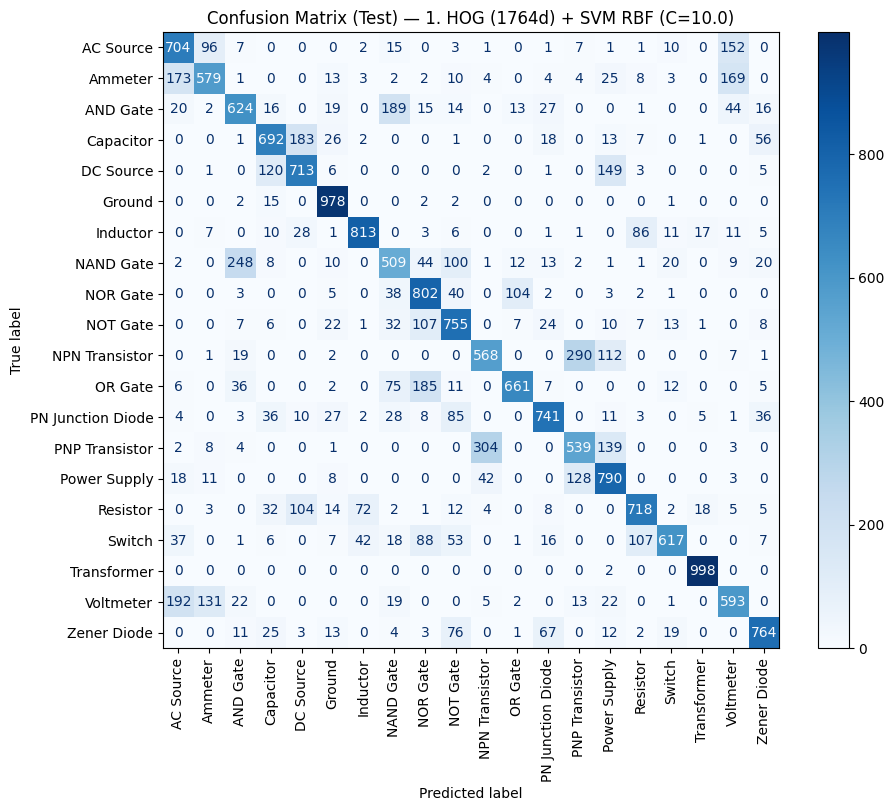


[1. HOG (1764d) + SVM RBF (C=10.0)] Tổng số ảnh dự đoán sai trên Test: 5842 / 20000


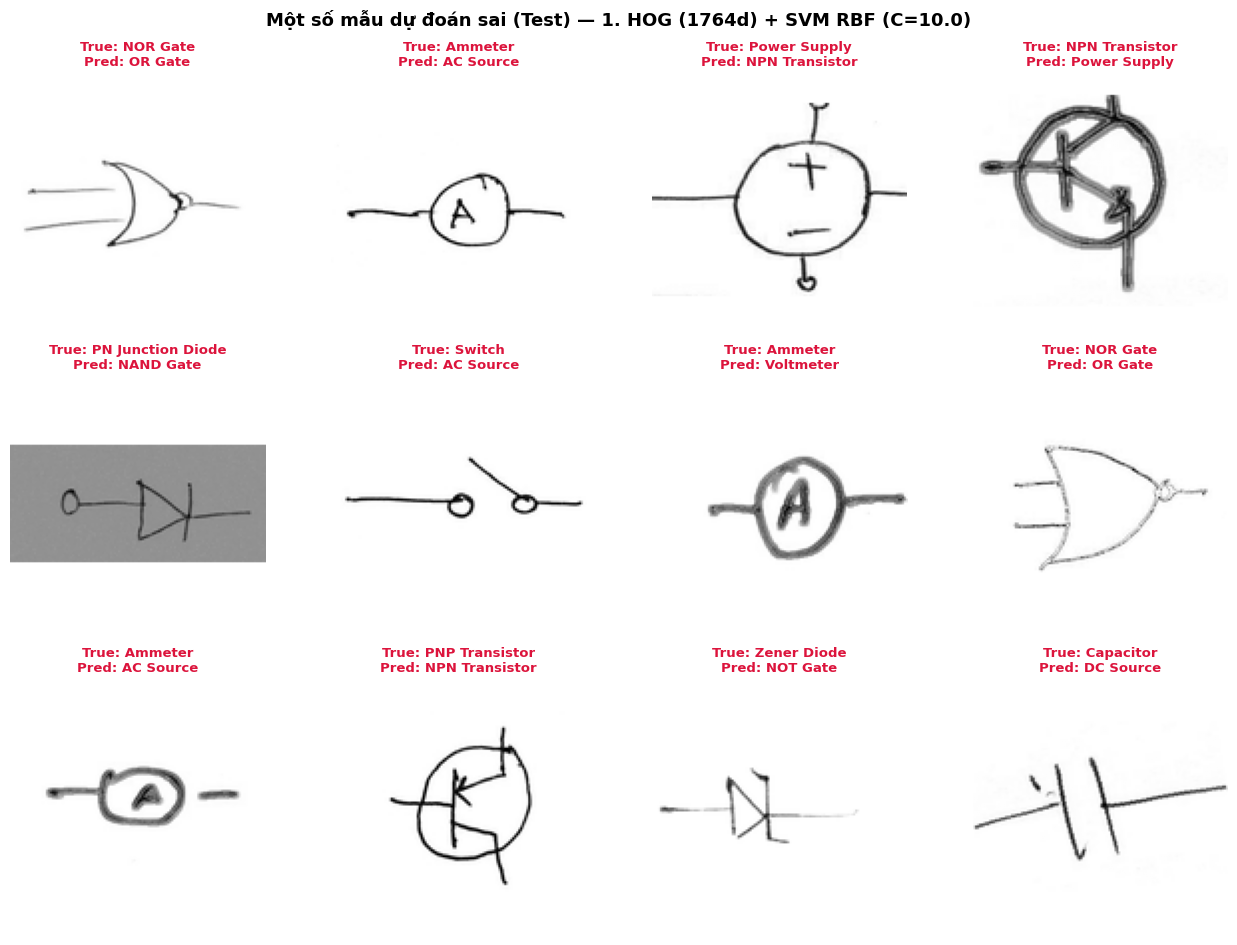

[CALIBRATION] Đã hiệu chuẩn xác suất trên Val | Tổng xác suất mẫu test: 1.0000


In [6]:
# --- BƯỚC 1: TIỀN XỬ LÝ & TRÍCH XUẤT HOG THUẦN ---
IMG_SIZE = 128
HOG_PARAMS = {
    "orientations": 9,
    "pixels_per_cell": (16, 16),
    "cells_per_block": (2, 2),
    "block_norm": "L2-Hys",
    "feature_vector": True
}

def preprocess(path):
    with Image.open(path) as im:
        img = im.convert("L")
        img = ImageOps.contain(img, (IMG_SIZE, IMG_SIZE), method=Image.Resampling.LANCZOS)
        canvas = Image.new("L", (IMG_SIZE, IMG_SIZE), 255)
        x = (IMG_SIZE - img.width) // 2
        y = (IMG_SIZE - img.height) // 2
        canvas.paste(img, (x, y))
    return np.asarray(canvas, dtype=np.float32) / 255.0

def extract_hog(path):
    img = preprocess(path)
    return hog(img, **HOG_PARAMS).astype(np.float32)

def extract_dataset(paths):
    features = []
    for i, path in enumerate(paths):
        features.append(extract_hog(path))
        if (i + 1) % 2000 == 0:
            print(f"Processed HOG {i+1}/{len(paths)}")
    return np.stack(features)

print("Dang trich xuat HOG cho Train...")
X_train = extract_dataset(train_paths)
print("\nDang trich xuat HOG cho Val...")
X_val = extract_dataset(val_paths)
print("\nDang trich xuat HOG cho Test...")
X_test = extract_dataset(test_paths)

print("\n===== KICH THUOC DU LIEU HOG =====")
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
assert X_train.shape[1] == 1764, "So chieu HOG khong dung (phai la 1764)"

# Chọn cấu hình tốt nhất trên Val -> Đánh giá Test & hiển thị ảnh dự đoán sai
res_hog = select_and_evaluate(
    "1. HOG (1764d)", X_train, y_train, X_val, y_val, X_test, y_test, test_paths
)

Dang trich xuat Shape (22d) cho Train...
Processed Shape 2000/8000
Processed Shape 4000/8000
Processed Shape 6000/8000
Processed Shape 8000/8000

Dang trich xuat Shape (22d) cho Val...
Processed Shape 2000/2000

Dang trich xuat Shape (22d) cho Test...
Processed Shape 2000/20000
Processed Shape 4000/20000
Processed Shape 6000/20000
Processed Shape 8000/20000
Processed Shape 10000/20000
Processed Shape 12000/20000
Processed Shape 14000/20000
Processed Shape 16000/20000
Processed Shape 18000/20000
Processed Shape 20000/20000

===== KICH THUOC DU LIEU HOG + SHAPE (22d) =====
X_train_hs: (8000, 1786) | X_val_hs: (2000, 1786) | X_test_hs: (20000, 1786)

ĐANG CHỌN CẤU HÌNH TRÊN VALIDATION CHO: 2. HOG + Shape (1786d)
  - Linear (C=1.0)   | Val Acc: 85.85% | Val F1: 0.8593 | Time: 9.46s
  - Linear (C=10.0)  | Val Acc: 85.85% | Val F1: 0.8593 | Time: 9.42s
  - RBF (C=1.0)      | Val Acc: 84.45% | Val F1: 0.8439 | Time: 25.50s
  - RBF (C=10.0)     | Val Acc: 86.15% | Val F1: 0.8611 | Time: 24.95s

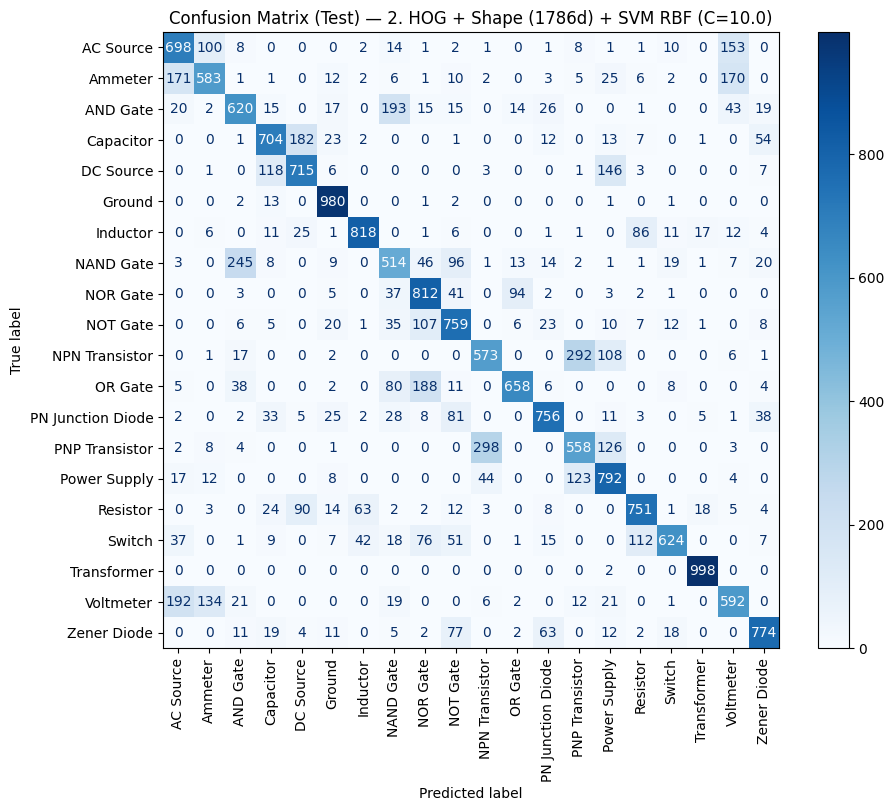


[2. HOG + Shape (1786d) + SVM RBF (C=10.0)] Tổng số ảnh dự đoán sai trên Test: 5721 / 20000


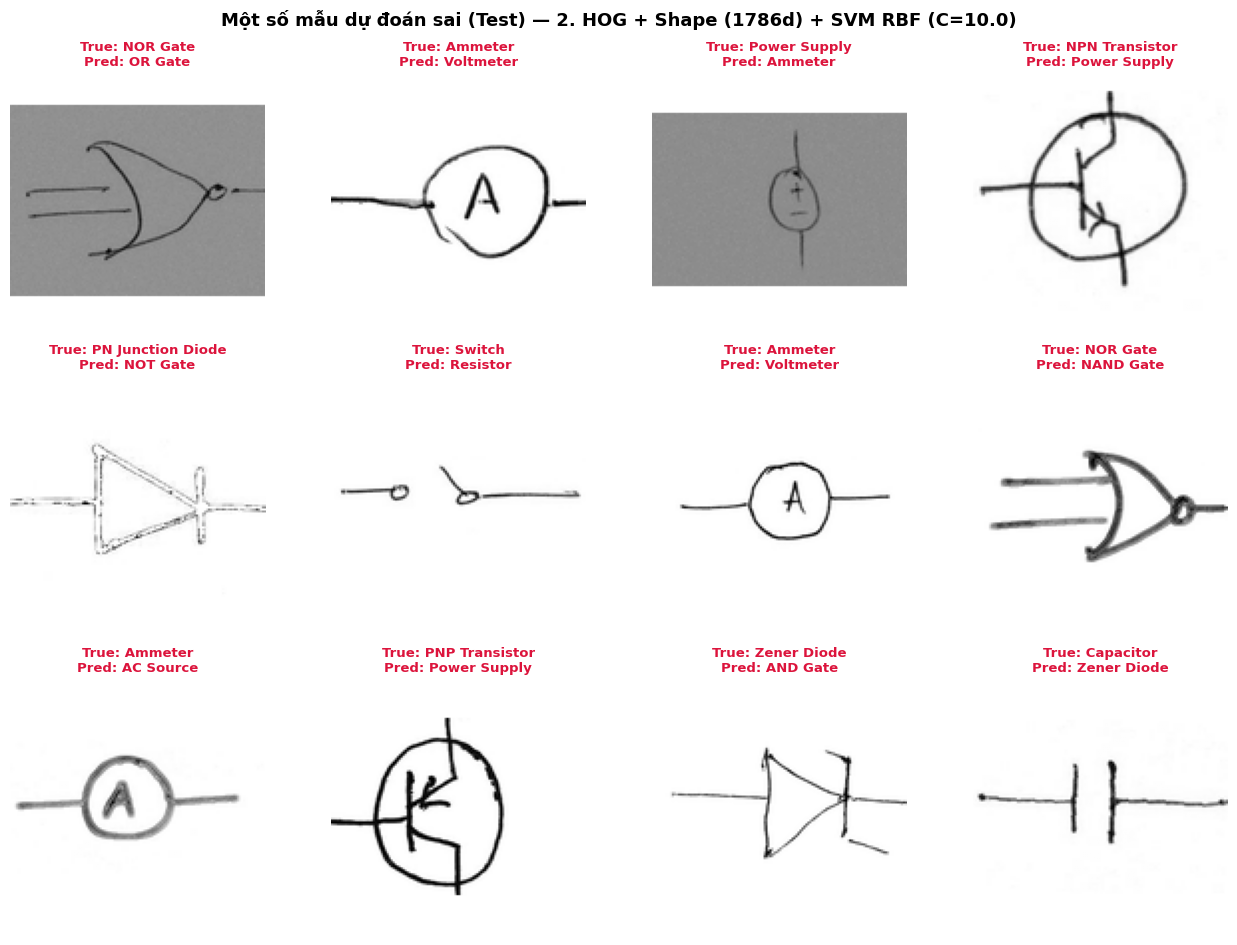

[CALIBRATION] Đã hiệu chuẩn xác suất trên Val | Tổng xác suất mẫu test: 1.0000


In [7]:
# --- BƯỚC 2: TRÍCH XUẤT SHAPE (22 CHIỀU) & GHÉP VỚI HOG ---
def extract_shape_features(img_float):
    gray_uint8 = (img_float * 255.0).astype(np.uint8)
    _, binary = cv2.threshold(gray_uint8, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    
    kernel = np.ones((3, 3), np.uint8)
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

    coords = cv2.findNonZero(binary)
    if coords is None:
        return np.zeros(22, dtype=np.float32)
    x, y, w, h = cv2.boundingRect(coords)
    roi = binary[y:y+h, x:x+w]

    # 7 Hu Moments (log)
    moments = cv2.moments(roi)
    hu = cv2.HuMoments(moments).flatten()
    hu_log = -np.sign(hu) * np.log10(np.abs(hu) + 1e-10)

    # 8 đặc trưng hình học & vùng bao cơ bản
    area = float(np.count_nonzero(roi))
    bbox_area = float(w * h)
    aspect_ratio = w / (h + 1e-5)
    extent = area / (bbox_area + 1e-5)
    norm_area = area / (IMG_SIZE * IMG_SIZE)

    contours, _ = cv2.findContours(roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) > 0:
        cnt = max(contours, key=cv2.contourArea)
        perimeter = cv2.arcLength(cnt, True)
        hull = cv2.convexHull(cnt)
        hull_area = cv2.contourArea(hull)
        hull_perimeter = cv2.arcLength(hull, True)
        solidity = area / (hull_area + 1e-5)
        circularity = (4 * np.pi * area) / (perimeter**2 + 1e-5)
        norm_perimeter = perimeter / (IMG_SIZE * 4.0)
        convexity = perimeter / (hull_perimeter + 1e-5)
    else:
        perimeter = hull_area = hull_perimeter = 0.0
        solidity = circularity = norm_perimeter = convexity = 0.0

    # 7 đặc trưng bổ sung từ regionprops & tỷ lệ không gian (tổng Shape = 22 chiều)
    roi_bool = (roi > 0).astype(np.uint8)
    props = regionprops(roi_bool)
    if len(props) > 0:
        eccentricity = float(props[0].eccentricity)
        euler_number = float(props[0].euler_number)
        major_axis = float(props[0].major_axis_length)
        minor_axis = float(props[0].minor_axis_length)
        filled_area = float(props[0].filled_area)
        equiv_diam = float(props[0].equivalent_diameter)
    else:
        eccentricity = euler_number = 0.0
        major_axis = minor_axis = filled_area = equiv_diam = 0.0

    axis_ratio = minor_axis / (major_axis + 1e-5)
    filled_ratio = filled_area / (area + 1e-5)
    bbox_norm_area = bbox_area / (IMG_SIZE * IMG_SIZE)
    hull_norm_area = hull_area / (IMG_SIZE * IMG_SIZE)
    equiv_diam_norm = equiv_diam / float(IMG_SIZE)
    compactness = area / (perimeter**2 + 1e-5)

    feats_22 = np.concatenate([
        hu_log.astype(np.float32),
        np.array([
            aspect_ratio, extent, solidity, eccentricity,
            circularity, euler_number, norm_area, norm_perimeter,
            bbox_norm_area, hull_norm_area, convexity,
            axis_ratio, filled_ratio, equiv_diam_norm, compactness
        ], dtype=np.float32)
    ])
    assert feats_22.shape[0] == 22, "So chieu Shape phai la 22"
    return feats_22

def extract_shape_dataset(paths):
    features = []
    for i, path in enumerate(paths):
        img = preprocess(path)
        features.append(extract_shape_features(img))
        if (i + 1) % 2000 == 0:
            print(f"Processed Shape {i+1}/{len(paths)}")
    return np.stack(features)

print("Dang trich xuat Shape (22d) cho Train...")
S_train = extract_shape_dataset(train_paths)
print("\nDang trich xuat Shape (22d) cho Val...")
S_val = extract_shape_dataset(val_paths)
print("\nDang trich xuat Shape (22d) cho Test...")
S_test = extract_shape_dataset(test_paths)

# Ghép HOG (1764) với Shape (22) -> 1786 chiều
X_train_hs = np.hstack([X_train, S_train])
X_val_hs   = np.hstack([X_val, S_val])
X_test_hs  = np.hstack([X_test, S_test])

print("\n===== KICH THUOC DU LIEU HOG + SHAPE (22d) =====")
print("X_train_hs:", X_train_hs.shape, "| X_val_hs:", X_val_hs.shape, "| X_test_hs:", X_test_hs.shape)
assert X_train_hs.shape[1] == 1786, "So chieu HOG + Shape phai la 1786"

# Chọn cấu hình tốt nhất trên Val -> Đánh giá Test & hiển thị ảnh dự đoán sai
res_hs = select_and_evaluate(
    "2. HOG + Shape (1786d)", X_train_hs, y_train, X_val_hs, y_val, X_test_hs, y_test, test_paths
)

Dang chay ReliefF tren rieng HOG (1764 -> 882)...
Hoan thanh ReliefF trong 164.76 giay!

===== KICH THUOC DU LIEU RELIEFF-HOG (882) + SHAPE (22) =====
X_train_rel_hs: (8000, 904) | X_val_rel_hs: (2000, 904) | X_test_rel_hs: (20000, 904)

ĐANG CHỌN CẤU HÌNH TRÊN VALIDATION CHO: 3. ReliefF-HOG + Shape (904d)
  - Linear (C=1.0)   | Val Acc: 86.05% | Val F1: 0.8608 | Time: 4.28s
  - Linear (C=10.0)  | Val Acc: 86.05% | Val F1: 0.8608 | Time: 4.31s
  - RBF (C=1.0)      | Val Acc: 86.60% | Val F1: 0.8647 | Time: 11.03s
  - RBF (C=10.0)     | Val Acc: 87.70% | Val F1: 0.8761 | Time: 10.94s

>>> CHỌN CẤU HÌNH TỐT NHẤT TRÊN VAL: RBF (C=10.0) (Val Acc: 87.70%)
>>> ĐÁNH GIÁ CHÍNH THỨC TRÊN TEST: 3. ReliefF-HOG + Shape (904d) + SVM RBF (C=10.0)
[TEST] Accuracy: 74.66% | Macro F1: 0.7445

Báo cáo chi tiết (TEST):
                   precision    recall  f1-score   support

        AC Source       0.61      0.72      0.66      1000
         AND Gate       0.62      0.64      0.63      1000
          

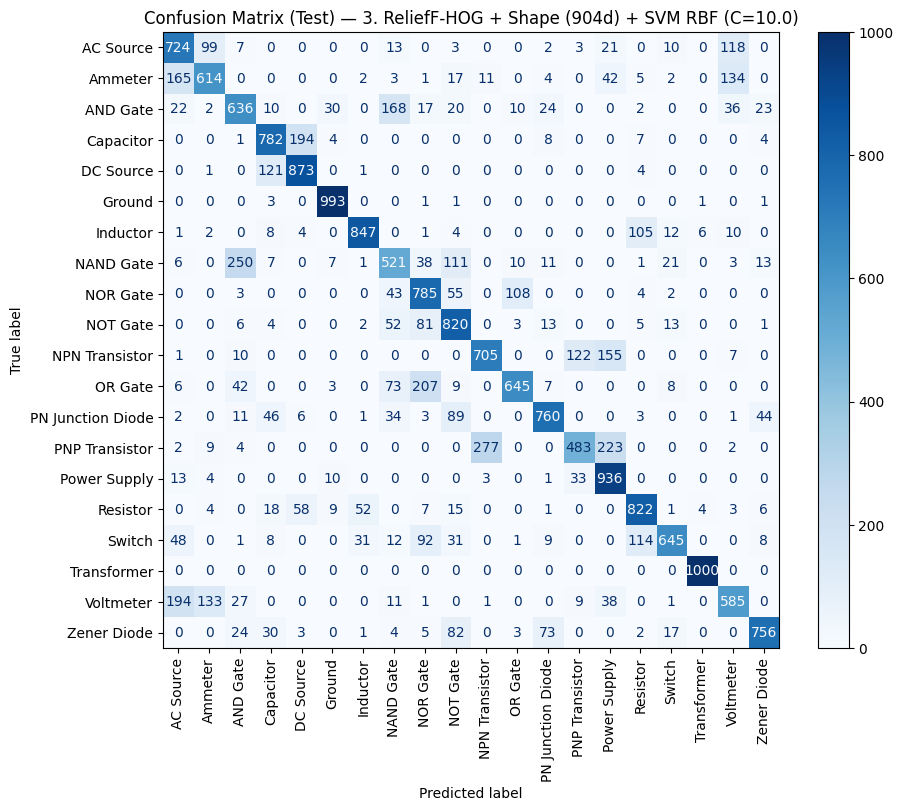


[3. ReliefF-HOG + Shape (904d) + SVM RBF (C=10.0)] Tổng số ảnh dự đoán sai trên Test: 5068 / 20000


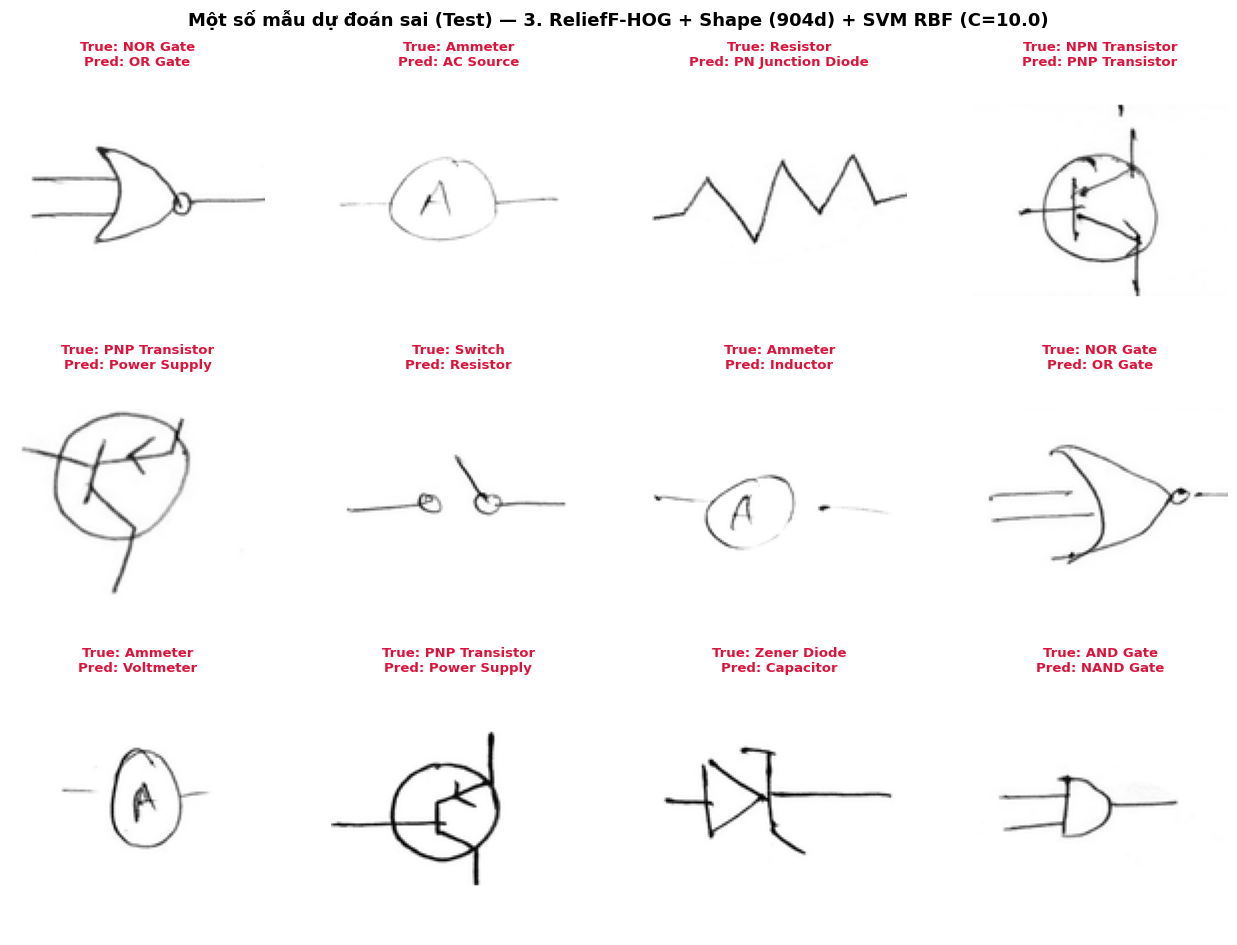

[CALIBRATION] Đã hiệu chuẩn xác suất trên Val | Tổng xác suất mẫu test: 1.0000


In [8]:
# --- BƯỚC 3: RELIEFF TRÊN HOG TRƯỚC (1764 -> 882), SAU ĐÓ GHÉP VỚI SHAPE (+22 = 904) ---
!pip install -q skrebate
from skrebate import ReliefF

N_RELIEFF_HOG = X_train.shape[1] // 2  # 1764 // 2 = 882 chiều

# 1. Chuẩn hóa riêng nhánh HOG trước khi tính khoảng cách trong ReliefF
scaler_hog = StandardScaler()
X_train_hog_sc = scaler_hog.fit_transform(X_train)
X_val_hog_sc   = scaler_hog.transform(X_val)
X_test_hog_sc  = scaler_hog.transform(X_test)

# 2. Lấy mẫu phân tầng 2500 ảnh từ Train để ReliefF chạy nhanh & không quá tải CPU
MAX_SAMPLES = 2500
sss = StratifiedShuffleSplit(n_splits=1, train_size=MAX_SAMPLES, random_state=SEED)
sub_idx, _ = next(sss.split(X_train_hog_sc, y_train))
X_fit = X_train_hog_sc[sub_idx]
y_fit = y_train[sub_idx].astype(int)

# 3. Khởi tạo và chạy ReliefF trên riêng HOG, giữ lại 882 đặc trưng tốt nhất
relieff = ReliefF(
    n_features_to_select=N_RELIEFF_HOG,
    n_neighbors=15,
    n_jobs=-1
)
print(f"Dang chay ReliefF tren rieng HOG (1764 -> {N_RELIEFF_HOG})...")
start_rel = time.time()
relieff.fit(X_fit, y_fit)
print(f"Hoan thanh ReliefF trong {time.time() - start_rel:.2f} giay!")

# 4. Giảm chiều riêng nhánh HOG xuống 882 chiều
X_train_hog_rel = relieff.transform(X_train_hog_sc)
X_val_hog_rel   = relieff.transform(X_val_hog_sc)
X_test_hog_rel  = relieff.transform(X_test_hog_sc)

# 5. Ghép 882 chiều ReliefF-HOG với 22 chiều Shape -> 904 chiều
X_train_rel_hs = np.hstack([X_train_hog_rel, S_train])
X_val_rel_hs   = np.hstack([X_val_hog_rel, S_val])
X_test_rel_hs  = np.hstack([X_test_hog_rel, S_test])

print("\n===== KICH THUOC DU LIEU RELIEFF-HOG (882) + SHAPE (22) =====")
print("X_train_rel_hs:", X_train_rel_hs.shape, "| X_val_rel_hs:", X_val_rel_hs.shape, "| X_test_rel_hs:", X_test_rel_hs.shape)
assert X_train_rel_hs.shape[1] == 904, "So chieu ReliefF-HOG + Shape phai la 904"

# 6. Chọn cấu hình tốt nhất trên Val -> Đánh giá Test & hiển thị ảnh dự đoán sai
res_rel_hs = select_and_evaluate(
    "3. ReliefF-HOG + Shape (904d)", X_train_rel_hs, y_train, X_val_rel_hs, y_val, X_test_rel_hs, y_test, test_paths
)

In [10]:
print("===== BẢNG TỔNG HỢP CHỌN CẤU HÌNH TRÊN VALIDATION =====")
df_val_all = pd.concat([res_hog["val_table"], res_hs["val_table"], res_rel_hs["val_table"]], ignore_index=True)
display(df_val_all)

print("\n===== BẢNG SO SÁNH MÔ HÌNH TỐT NHẤT TRÊN TEST =====")
df_test_summary = pd.DataFrame([
    {"Biểu diễn": "1. HOG (1764d)",                "Cấu hình tốt nhất": res_hog["best_cfg"],    "Test Acc (%)": round(res_hog["test_acc"]*100, 2),    "Test Macro F1": round(res_hog["test_f1"], 4)},
    {"Biểu diễn": "2. HOG + Shape (1786d)",        "Cấu hình tốt nhất": res_hs["best_cfg"],     "Test Acc (%)": round(res_hs["test_acc"]*100, 2),     "Test Macro F1": round(res_hs["test_f1"], 4)},
    {"Biểu diễn": "3. ReliefF-HOG + Shape (904d)", "Cấu hình tốt nhất": res_rel_hs["best_cfg"], "Test Acc (%)": round(res_rel_hs["test_acc"]*100, 2), "Test Macro F1": round(res_rel_hs["test_f1"], 4)},
])
display(df_test_summary)

np.savez_compressed(
    "/kaggle/working/circuit_features_all.npz",
    X_train=X_train, X_val=X_val, X_test=X_test,
    X_train_hs=X_train_hs, X_val_hs=X_val_hs, X_test_hs=X_test_hs,
    X_train_rel_hs=X_train_rel_hs, X_val_rel_hs=X_val_rel_hs, X_test_rel_hs=X_test_rel_hs,
    y_train=y_train, y_val=y_val, y_test=y_test
)
print("Da luu toan bo dac trung thanh cong tai /kaggle/working/circuit_features_all.npz!")

model_save_path = "/kaggle/working/trained_svm_models.joblib"
checkpoint = {
    "config": {
        "img_size": IMG_SIZE,
        "hog_params": HOG_PARAMS,
        "shape_dim": 22,
        "relieff_hog_dim": N_RELIEFF_HOG,
        "label_map": LABEL_MAP,
        "class_names": CLASS_NAMES,
    },
    "hog_best": res_hog["best_model"],
    "hog_shape_best": res_hs["best_model"],
    "relieff_hog_transform": {
        "scaler_hog": scaler_hog,
        "relieff": relieff,
    },
    "relieff_hog_shape_best": res_rel_hs["best_model"],
    "val_results": df_val_all,
    "test_summary": df_test_summary,
}
joblib.dump(checkpoint, model_save_path)
size_mb = os.path.getsize(model_save_path) / (1024 * 1024)
print(f"Da luu mo hinh da train (khong nen) tai: {model_save_path} ({size_mb:.2f} MB)")

===== BẢNG TỔNG HỢP CHỌN CẤU HÌNH TRÊN VALIDATION =====


,Đặc trưng,Cấu hình,Val Acc (%),Val Macro F1,Train Time (s)
0,1. HOG (1764d),Linear (C=1.0),85.15,0.8524,9.38
1,1. HOG (1764d),Linear (C=10.0),85.15,0.8524,9.30
2,1. HOG (1764d),RBF (C=1.0),83.90,0.8386,25.27
3,1. HOG (1764d),RBF (C=10.0),85.80,0.8578,24.99
4,2. HOG + Shape (1786d),Linear (C=1.0),85.85,0.8593,9.46
5,2. HOG + Shape (1786d),Linear (C=10.0),85.85,0.8593,9.42
6,2. HOG + Shape (1786d),RBF (C=1.0),84.45,0.8439,25.50
7,2. HOG + Shape (1786d),RBF (C=10.0),86.15,0.8611,24.95
8,3. ReliefF-HOG + Shape (904d),Linear (C=1.0),86.05,0.8608,4.28
9,3. ReliefF-HOG + Shape (904d),Linear (C=10.0),86.05,0.8608,4.31



===== BẢNG SO SÁNH MÔ HÌNH TỐT NHẤT TRÊN TEST =====


,Biểu diễn,Cấu hình tốt nhất,Test Acc (%),Test Macro F1
0,1. HOG (1764d),RBF (C=10.0),70.79,0.7071
1,2. HOG + Shape (1786d),RBF (C=10.0),71.39,0.7133
2,3. ReliefF-HOG + Shape (904d),RBF (C=10.0),74.66,0.7445


Da luu toan bo dac trung thanh cong tai /kaggle/working/circuit_features_all.npz!
Da luu mo hinh da train (khong nen) tai: /kaggle/working/trained_svm_models.joblib (205.14 MB)


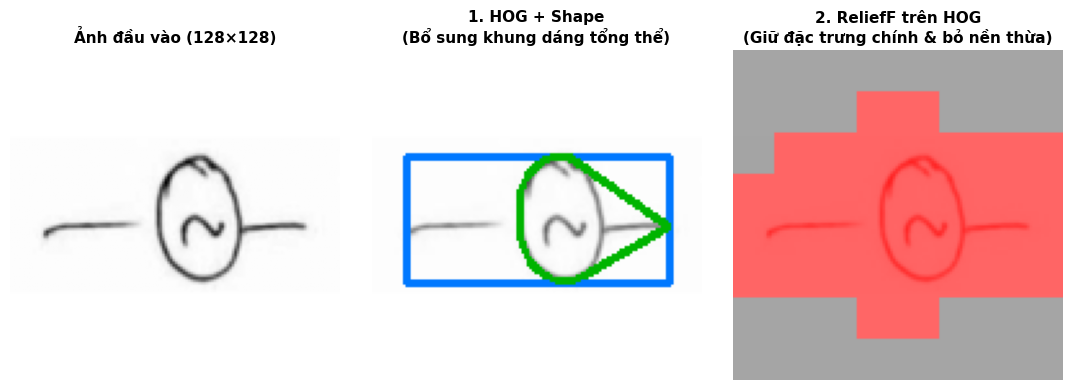

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Lấy ảnh gốc đầu tiên của dataset
sample_path = originals[0]
img_float = preprocess(sample_path)
gray_uint8 = (img_float * 255.0).astype(np.uint8)

# 2. Tính minh họa Shape (Khung bao & Đường bao lồi)
_, binary = cv2.threshold(gray_uint8, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
x, y, w, h = cv2.boundingRect(cv2.findNonZero(binary))
cnt = max(cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
hull = cv2.convexHull(cnt)

vis_shape = cv2.cvtColor(gray_uint8, cv2.COLOR_GRAY2RGB)
cv2.rectangle(vis_shape, (x, y), (x + w, y + h), (0, 120, 255), 2) # Khung bao (Xanh dương)
cv2.drawContours(vis_shape, [hull], -1, (0, 180, 0), 2)           # Đường bao lồi (Xanh lá)

# 3. Tính minh họa ReliefF trên HOG (chỉ vẽ vùng lọc ReliefF, không vẽ Shape)
hog_scores = relieff.feature_importances_[:1764]
block_scores = hog_scores.reshape(7, 7, 36).mean(axis=2)

pixel_weights = np.zeros((8, 8))
counts = np.zeros((8, 8))
for r in range(7):
    for c in range(7):
        pixel_weights[r:r+2, c:c+2] += block_scores[r, c]
        counts[r:r+2, c:c+2] += 1
cell_importance = pixel_weights / counts

heatmap = cv2.resize(cell_importance, (128, 128), interpolation=cv2.INTER_NEAREST)
heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)

mask_keep = (heatmap > np.percentile(heatmap, 45)).astype(np.float32)
vis_relieff = cv2.cvtColor(gray_uint8, cv2.COLOR_GRAY2RGB)

# Tô màu đỏ nhẹ vùng HOG được ReliefF giữ lại & làm mờ xám nền thừa
vis_relieff[mask_keep == 1, 0] = 255
vis_relieff[mask_keep == 1, 1] = (vis_relieff[mask_keep == 1, 1] * 0.4).astype(np.uint8)
vis_relieff[mask_keep == 1, 2] = (vis_relieff[mask_keep == 1, 2] * 0.4).astype(np.uint8)
vis_relieff[mask_keep == 0] = (vis_relieff[mask_keep == 0] * 0.65).astype(np.uint8)

# 4. Hiển thị 3 bước nối tiếp nhau
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))

axes[0].imshow(gray_uint8, cmap="gray")
axes[0].set_title("Ảnh đầu vào (128×128)", fontsize=11, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(vis_shape)
axes[1].set_title("1. HOG + Shape\n(Bổ sung khung dáng tổng thể)", fontsize=11, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(vis_relieff)
axes[2].set_title("2. ReliefF trên HOG\n(Giữ đặc trưng chính & bỏ nền thừa)", fontsize=11, fontweight="bold")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/slide3_truc_quan.png", dpi=200, bbox_inches="tight")
plt.show()